In [22]:
!pip install ultralytics

In [6]:
import numpy as np
import pandas as pd
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt


In [ ]:
!unzip /content/object_detection.v1i.yolov11.zip

Archive:  /content/object_detection.v1i.yolov11.zip
replace test/images/Screenshot-2026-11-11-095302_png.rf.2b2d1c150b21536dc0ff2c30a4d1f46b.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: N
  inflating: valid/labels/Screenshot-2026-11-11-100250_png.rf.bdda3e2b2c49dfc3fd93f58f3043f331.txt  
  inflating: valid/labels/Screenshot-2026-11-11-093503_png.rf.0b52f2c02c96d553124ceb91391fe6c4.txt  
  inflating: valid/labels/Screenshot-2026-11-11-093118_png.rf.3cf5024b88b4222ffd99d64e792b7b55.txt  
  inflating: valid/labels/Screenshot-2026-11-11-094050_png.rf.ed411397314435e16cdff83db165dcf8.txt  
  inflating: README.roboflow.txt     
  inflating: README.dataset.txt      


In [23]:
import shutil
import os

base_path = "/content/runs/detect"

folders_to_delete = [ "hotel_detection","train","predict", "predict-2",]

for folder in folders_to_delete:
    path = os.path.join(base_path, folder)

    if os.path.exists(path):
        shutil.rmtree(path)
        print(f"Deleted: {folder}")

print("Remaining training folder: train")

Deleted: hotel_detection
Deleted: train
Deleted: predict
Deleted: predict-2
Remaining training folder: train


In [24]:
model = YOLO('yolo11n.pt')

In [25]:
#results  = model.train(data = "/content/data.yaml",epochs = 100, imgsz = 640)
results = model.train(
    data="/content/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,exist_ok =True)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, 

In [26]:
fine_tuned_model = YOLO('/content/runs/detect/train/weights/best.pt')

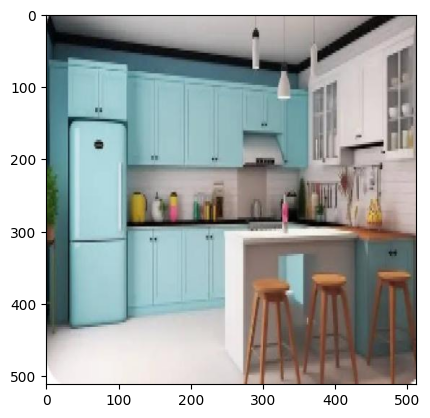

In [42]:
img1 = cv2.imread('/content/test/images/Screenshot-2026-11-11-095957_png.rf.290321ee163d6cbfc049ec1deac75e1c.jpg')
img1 = cv2.cvtColor(img1 , cv2.COLOR_BGR2RGB)
plt.imshow(img1)
plt.show()

In [39]:
result = fine_tuned_model(img1, save = True)
result


0: 640x640 1 refridgerator, 9.6ms
Speed: 3.0ms preprocess, 9.6ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 colors: None
 depth: None
 keypoints: None
 masks: None
 names: {0: 'AC', 1: 'bed', 2: 'chair', 3: 'clock', 4: 'dinning table', 5: 'dressing_table', 6: 'fan', 7: 'refridgerator', 8: 'sofa', 9: 'television', 10: 'wardrobe', 11: 'window'}
 obb: None
 orig_img: array([[[255, 255, 255],
         [249, 249, 251],
         [249, 249, 251],
         ...,
         [172, 167, 164],
         [171, 166, 163],
         [171, 166, 163]],
 
        [[255, 255, 255],
         [255, 255, 255],
         [255, 255, 255],
         ...,
         [171, 166, 163],
         [171, 166, 163],
         [170, 165, 162]],
 
        [[247, 247, 249],
         [255, 255, 255],
         [248, 248, 250],
         ...,
         [170, 165, 162],
         [170, 165, 162],
         [169, 164, 161]],
 
        ...,
 
        [[252, 255, 255],
         [252, 255, 255],
         [252, 255, 255],
         ...,
     

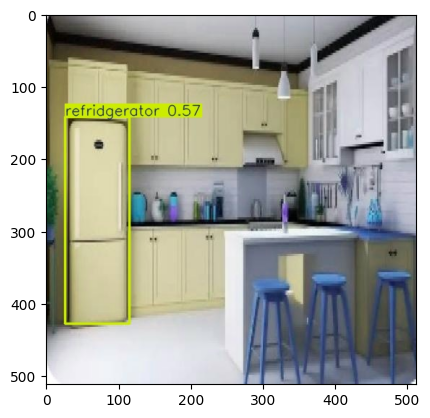

In [43]:
pred = cv2.imread('/content/runs/detect/predict/image0.jpg')
pred_img = cv2.cvtColor(pred , cv2.COLOR_BGR2RGB)
plt.imshow(pred_img)

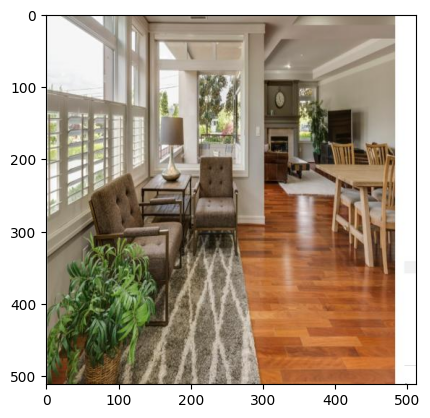

In [48]:
img2 = '/content/test/images/Screenshot-2026-11-11-094538_png.rf.b968313636a45bce42b8f30b7946c926.jpg'
img2 = cv2.imread(img2)
img2 = cv2.cvtColor(img2 , cv2.COLOR_BGR2RGB)
plt.imshow(img2)

In [49]:
results =fine_tuned_model(img2 ,save =True ,conf = 0.60)
results


0: 640x640 1 window, 10.7ms
Speed: 3.3ms preprocess, 10.7ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 colors: None
 depth: None
 keypoints: None
 masks: None
 names: {0: 'AC', 1: 'bed', 2: 'chair', 3: 'clock', 4: 'dinning table', 5: 'dressing_table', 6: 'fan', 7: 'refridgerator', 8: 'sofa', 9: 'television', 10: 'wardrobe', 11: 'window'}
 obb: None
 orig_img: array([[[254, 254, 254],
         [233, 233, 233],
         [243, 243, 243],
         ...,
         [255, 255, 255],
         [255, 255, 255],
         [255, 255, 255]],
 
        [[254, 254, 254],
         [233, 233, 233],
         [243, 243, 243],
         ...,
         [255, 255, 255],
         [255, 255, 255],
         [255, 255, 255]],
 
        [[254, 254, 254],
         [233, 233, 233],
         [243, 243, 243],
         ...,
         [255, 255, 255],
         [255, 255, 255],
         [255, 255, 255]],
 
        ...,
 
        [[255, 248, 239],
         [150, 131, 117],
         [ 58,  49,  32],
         ...,
     

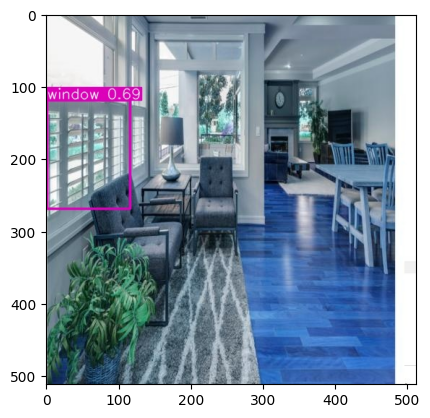

In [50]:
p_img = cv2.imread('/content/runs/detect/predict/image0.jpg')
p_img = cv2.cvtColor(p_img, cv2.COLOR_BGR2RGB)
plt.imshow(p_img)

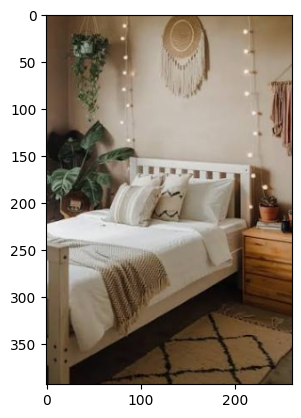

In [52]:

img3 = '/content/Screenshot 2026-11-12 161418.png'
img3 = cv2.imread(img3)
img3 = cv2.cvtColor(img3 , cv2.COLOR_BGR2RGB)
plt.imshow(img3)

In [53]:
result =fine_tuned_model(img3 ,save =True ,conf = 0.60)
result


0: 640x448 1 bed, 36.9ms
Speed: 2.5ms preprocess, 36.9ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 448)
Results saved to /content/runs/detect/predict


[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 colors: None
 depth: None
 keypoints: None
 masks: None
 names: {0: 'AC', 1: 'bed', 2: 'chair', 3: 'clock', 4: 'dinning table', 5: 'dressing_table', 6: 'fan', 7: 'refridgerator', 8: 'sofa', 9: 'television', 10: 'wardrobe', 11: 'window'}
 obb: None
 orig_img: array([[[ 93,  67,  46],
         [ 92,  66,  46],
         [ 92,  66,  46],
         ...,
         [121,  93,  54],
         [121,  93,  54],
         [121,  92,  53]],
 
        [[ 93,  67,  46],
         [ 92,  66,  46],
         [ 92,  66,  46],
         ...,
         [122,  94,  54],
         [122,  94,  54],
         [122,  93,  54]],
 
        [[ 93,  67,  46],
         [ 92,  66,  46],
         [ 92,  66,  46],
         ...,
         [123,  95,  55],
         [122,  94,  55],
         [122,  94,  55]],
 
        ...,
 
        [[ 17,   9,   7],
         [ 17,   9,   4],
         [ 42,  32,  23],
         ...,
     

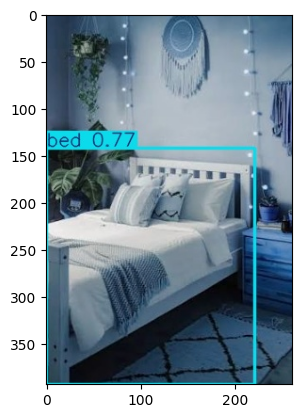

In [54]:
p_img = cv2.imread('/content/runs/detect/predict/image0.jpg')
p_img = cv2.cvtColor(p_img, cv2.COLOR_BGR2RGB)
plt.imshow(p_img)